# Separação de vértebras em rótulos de segmentação

Este notebook é a camada de **visualização e QA** sobre o algoritmo de separação de vértebras.
O algoritmo em si vive em `vfss_data_split.target.vertebra` e é o mesmo que o pipeline usa
(`tasks/create_video_frame_dataset.py`, seção `target_variants` do YAML) — aqui não há cópia dele.

Use este notebook para calibrar os parâmetros de clusterização olhando os resultados frame a frame,
e depois fixe os valores escolhidos no `configs/data/*.yaml`.


In [1]:
from pathlib import Path
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from IPython.display import clear_output, display

repo = Path.cwd()
while repo.parent != repo and not (repo / "src" / "vfss_data_split").exists():
    repo = repo.parent
os.chdir(repo)
if str(repo / "src") not in sys.path:
    sys.path.insert(0, str(repo / "src"))

# Algoritmo compartilhado com o pipeline - fonte unica de verdade, sem duplicacao aqui.
from vfss_data_split.target.vertebra import (
    ClusteringParams,
    binarize_labels,
    cluster_vertebrae,
    component_stats,
    connected_component_labels,
    labels_to_image_array,
    select_vertebrae,
    to_foreground_mask,
    watershed_labels,
)
from vfss_data_split.target.variants import (
    MANIFEST_FILENAME,
    VariantSpec,
    generate_target_variants,
    targets_dir,
    variant_relative_path,
)
from vfss_data_split.data_extraction.video_frame import load_video_frame_metadata_from_csv

print(repo)



KeyboardInterrupt



## Parâmetros — escolha do dataset

Tudo neste notebook vem de um `configs/data/<nome>.yaml`, **a mesma config que o pipeline usa**:
o CSV do dataset, a modalidade e variante base, os parâmetros de clusterização, a pasta das
máscaras corrigidas e a fila de revisão. Trocar `CONFIG_NAME` troca o dataset inteiro — não há
caminho repetido à mão em célula nenhuma.

`available_configs()` lista o que existe (hoje: `inca-vfss`, `unm-vfss`). Os caminhos do YAML
são resolvidos em relação ao diretório do próprio YAML, e o CSV aberto é o que mora **dentro do
dataset** — é o diretório dele que `load_video_frame_metadata_from_csv` usa como raiz para
resolver `image_path`/`target_path`.

In [ ]:
from vfss_data_split.config import PipelineConfig, available_configs

# >>> Escolha o dataset aqui. Nome de um configs/data/*.yaml (sem a extensao). <<<
CONFIG_NAME = "inca-vfss"      # ex.: "unm-vfss"

print("configs disponiveis:", sorted(available_configs()))
CONFIG = PipelineConfig.load(CONFIG_NAME)
print(CONFIG.describe())

# Tudo abaixo vem da config -- nao edite a mao, edite o YAML.
DATASET_CSV = Path(CONFIG.dataset_csv)
TARGET_TYPE = CONFIG.target_type          # modalidade: targets/<TARGET_TYPE>/...
BASE_VARIANT = CONFIG.base_variant        # variante lida como entrada da clusterizacao
AREA_RATIO_THRESHOLD = CONFIG.area_ratio_threshold
FIXES_DIR = Path(CONFIG.fixed_masks.dir)              # mascaras corrigidas a mao (napari)
REVIEW_QUEUE_PATH = Path(CONFIG.fixed_masks.review_queue_path)  # fila do que falta corrigir

# Espelha target_variants.params.clustering do YAML. Cada `method` processa o frame inteiro de
# uma vez -- nao ha mistura de dois metodos dentro de um mesmo frame. Para EXPERIMENTAR outro
# metodo sem mexer no YAML, sobrescreva aqui e rode as celulas de novo; o que ficar bom, fixe
# no YAML depois:
#     from dataclasses import replace
#     CLUSTERING = replace(CLUSTERING, method="watershed")
CLUSTERING = CONFIG.clustering

MAX_DATASET_FILES = None   # use um inteiro para limitar durante testes rapidos.
CURRENT_INDEX = 0

# Vertebras a inspecionar/exportar.
SELECTED_VERTEBRAE = ["C2", "C3", "C4"]

# Binarizacao da mascara de entrada: None aceita qualquer valor > FOREGROUND_THRESHOLD.
BINARY_VALUES = None
FOREGROUND_THRESHOLD = 0


configs disponiveis: ['inca-vfss', 'inca-vfss-batch-5', 'unm-vfss']
config:        /Users/caioseda/Documents/Trabalho/Tecgraf/projetos/vfss-data-split/configs/data/inca-vfss.yaml
dataset:       /Users/caioseda/Documents/Trabalho/Tecgraf/projetos/dados_inca/dataset
CSV:           /Users/caioseda/Documents/Trabalho/Tecgraf/projetos/dados_inca/dataset/inca-video-frame-dataset.csv
target:        mask | variante base: raw
clusterizacao: connected_components
correcoes:     /Users/caioseda/Documents/Trabalho/Tecgraf/projetos/vfss-data-split/data/mascaras-corrigidas (enabled=True)
fila:          /Users/caioseda/Documents/Trabalho/Tecgraf/projetos/vfss-data-split/data/metadados/inca-mascaras-para-corrigir.csv


In [ ]:
def load_image(path):
    """Le uma mascara ou frame do disco como array numpy."""
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(path)
    return np.asarray(Image.open(path))


def normalize_image_for_display(arr):
    """Normaliza um frame para exibicao, cortando nos percentis 1 e 99."""
    if arr is None:
        return None
    arr = np.squeeze(np.asarray(arr).astype(np.float32))
    if arr.ndim == 3 and arr.shape[-1] in (3, 4):
        arr = arr[..., :3]
    lo, hi = np.nanpercentile(arr, [1, 99])
    return np.clip((arr - lo) / (hi - lo + 1e-8), 0, 1)


## Índice de máscaras

Construído a partir do CSV do dataset: uma linha por `video_frame`, com o caminho da máscara base
(`targets/<modalidade>/<base>/<labeler>/`) e do frame correspondente (`frames/<video_id>/`).


In [ ]:
def build_mask_index(dataset_csv=None, target_type=None, variant=None, max_files=None):
    """Indice de mascaras a partir do CSV do dataset, com caminhos absolutos resolvidos."""
    dataset_csv = Path(dataset_csv or DATASET_CSV)
    target_type = target_type or TARGET_TYPE
    variant = variant or BASE_VARIANT

    df = load_video_frame_metadata_from_csv(path=str(dataset_csv))
    root = Path(df.attrs["base_dir"])

    rows = []
    for idx, row in df.reset_index(drop=True).iterrows():
        relative = variant_relative_path(target_type, variant, row.selected_labeler, row.video_frame)
        label_path = root / relative
        rows.append({
            "index": idx,
            "video_frame": row.video_frame,
            "video_id": row.video_id,
            "frame_id": row.frame_id,
            "labeler": row.selected_labeler,
            "label_path": str(label_path),
            "image_path": str(root / row.image_path),
            "filename": label_path.name,
        })

    index_df = pd.DataFrame(rows)
    if max_files is not None:
        index_df = index_df.head(int(max_files)).copy()
    return index_df


mask_index = build_mask_index(max_files=MAX_DATASET_FILES)
DATASET_ROOT = Path(load_video_frame_metadata_from_csv(path=str(DATASET_CSV)).attrs["base_dir"])
print(f"Máscaras encontradas: {len(mask_index)} | raiz do dataset: {DATASET_ROOT}")
display(mask_index.head())


Máscaras encontradas: 961 | raiz do dataset: /Users/caioseda/Documents/Trabalho/Tecgraf/projetos/dados_inca/dataset


,index,video_frame,video_id,frame_id,labeler,label_path,image_path,filename
0,0,v100_f10,100,10,VC,/Users/caioseda/Documents/Trabalho/Tecgraf/pro...,/Users/caioseda/Documents/Trabalho/Tecgraf/pro...,v100_f10.tif
1,1,v100_f12,100,12,AM,/Users/caioseda/Documents/Trabalho/Tecgraf/pro...,/Users/caioseda/Documents/Trabalho/Tecgraf/pro...,v100_f12.tif
2,2,v100_f13,100,13,BB,/Users/caioseda/Documents/Trabalho/Tecgraf/pro...,/Users/caioseda/Documents/Trabalho/Tecgraf/pro...,v100_f13.tif
3,3,v100_f14,100,14,BB,/Users/caioseda/Documents/Trabalho/Tecgraf/pro...,/Users/caioseda/Documents/Trabalho/Tecgraf/pro...,v100_f14.tif
4,4,v100_f15,100,15,VC,/Users/caioseda/Documents/Trabalho/Tecgraf/pro...,/Users/caioseda/Documents/Trabalho/Tecgraf/pro...,v100_f15.tif


## Carregamento e máscara binária

Amostra 1/961 | v100_f10 | labeler=VC
LABEL_PATH: /Users/caioseda/Documents/Trabalho/Tecgraf/projetos/dados_inca/dataset/targets/mask/raw/VC/v100_f10.tif
IMAGE_PATH: /Users/caioseda/Documents/Trabalho/Tecgraf/projetos/dados_inca/dataset/frames/100/10.png
label_raw shape: (1024, 1024) dtype: uint8
foreground pixels: 38032


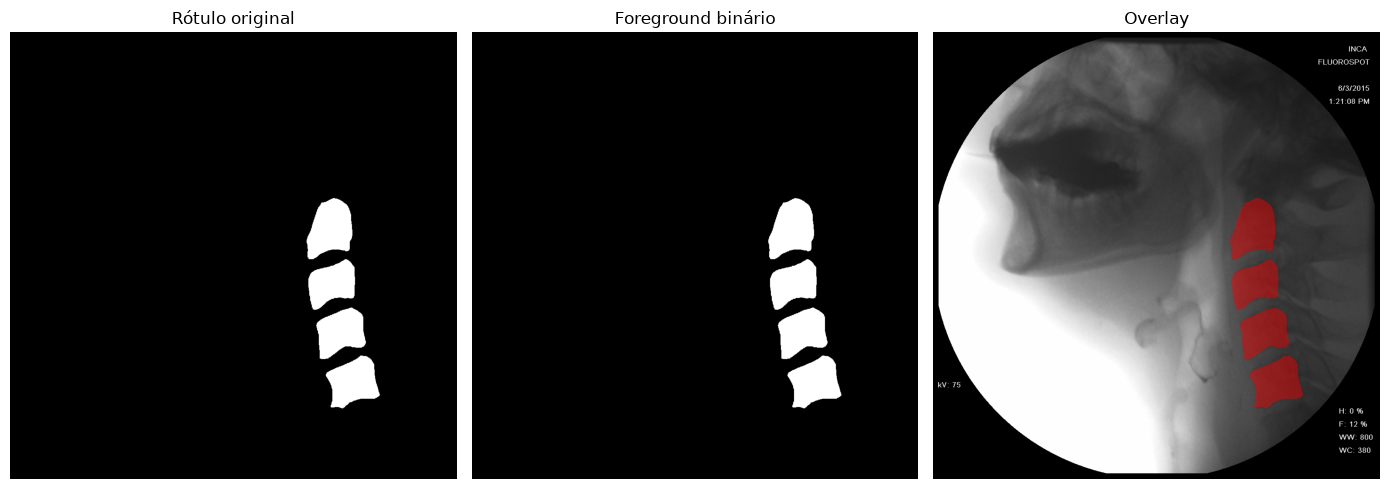

In [ ]:
if mask_index.empty:
    raise ValueError(f"Nenhuma máscara indexada. Verifique {DATASET_CSV}.")

CURRENT_INDEX = int(np.clip(CURRENT_INDEX, 0, len(mask_index) - 1))
current_row = mask_index.iloc[CURRENT_INDEX]
LABEL_PATH = Path(current_row["label_path"])
IMAGE_PATH = Path(current_row["image_path"])
print(f"Amostra {CURRENT_INDEX + 1}/{len(mask_index)} | {current_row['video_frame']} | labeler={current_row['labeler']}")
print("LABEL_PATH:", LABEL_PATH)
print("IMAGE_PATH:", IMAGE_PATH)

label_raw = load_image(LABEL_PATH)
foreground = to_foreground_mask(label_raw, BINARY_VALUES, FOREGROUND_THRESHOLD)
image_display = normalize_image_for_display(load_image(IMAGE_PATH)) if IMAGE_PATH.exists() else None

print("label_raw shape:", label_raw.shape, "dtype:", label_raw.dtype)
print("foreground pixels:", int(foreground.sum()))

fig, axes = plt.subplots(1, 2 if image_display is None else 3, figsize=(14, 5))
axes = np.atleast_1d(axes)
axes[0].imshow(label_raw, cmap="gray")
axes[0].set_title("Rótulo original")
axes[0].axis("off")
axes[1].imshow(foreground, cmap="gray")
axes[1].set_title("Foreground binário")
axes[1].axis("off")
if image_display is not None:
    axes[2].imshow(image_display, cmap="gray")
    axes[2].imshow(np.ma.masked_where(~foreground, foreground), cmap="autumn", alpha=0.45)
    axes[2].set_title("Overlay")
    axes[2].axis("off")
plt.tight_layout()


## Separação das vértebras

`cluster_vertebrae` aplica o método escolhido em `CLUSTERING` (componentes conectados ou k-means
no eixo anatômico) e já devolve os clusters nomeados C2, C3, C4... em ordem anatômica.


In [ ]:
vertebra_labels, vertebra_stats = cluster_vertebrae(foreground, CLUSTERING)
display(vertebra_stats)


,label_id,area,centroid_axis0,centroid_axis1,min_axis0,max_axis0,min_axis1,max_axis1,ordered_id,vertebra
0,1,10458,450.048862,733.899407,380,519,680,784,1,C2
1,2,8573,575.736615,737.380497,520,635,684,790,2,C3
2,3,9231,686.991225,757.503087,631,748,702,815,3,C4
3,4,9770,801.544012,786.473593,741,861,724,847,4,C5


## Comparação dos métodos

Cada `method` processa o frame inteiro de uma vez — nunca há mistura de dois métodos dentro do
mesmo frame. `connected_components` funde vértebras que se tocam; `watershed` (experimental)
trata o fundo como marcador próprio e separa mesmo sem gap, mas às vezes gera um fragmento
espúrio numa quina do blob fundido (ver README); `axis_kmeans` reparticiona a máscara inteira em
faixas perpendiculares a um eixo fixo, cego à forma — corta vértebras ao meio com a coluna
inclinada.


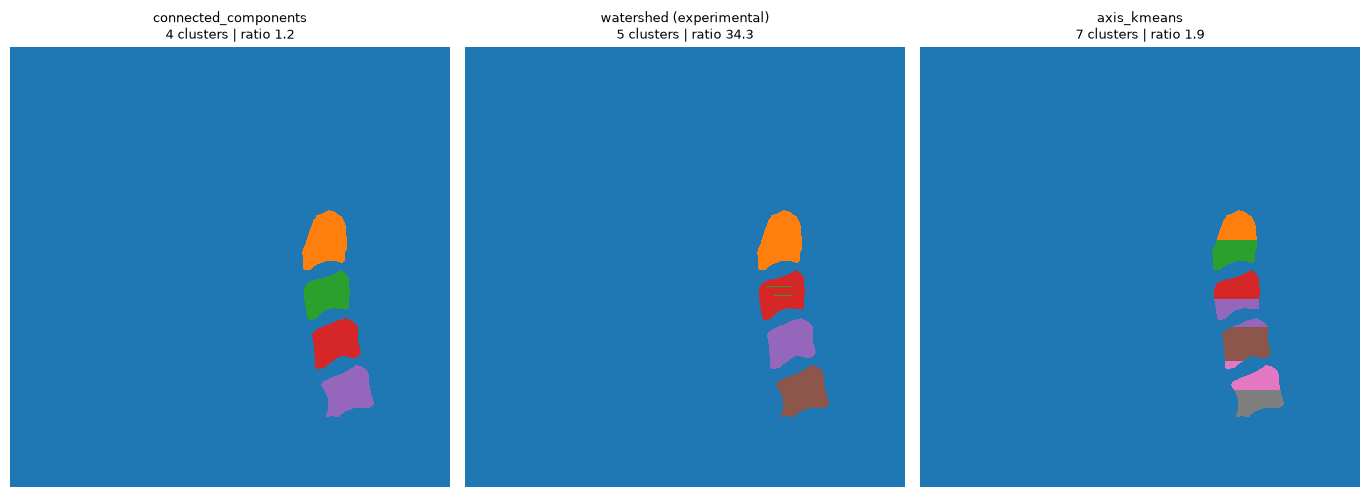

In [ ]:
# Compara os metodos na amostra atual, para decidir qual usar nesse frame antes de fixar no YAML.
def _ratio(lab):
    a = component_stats(lab).area
    return (a.max() / max(a.min(), 1)) if len(a) else float("nan")

variantes = {
    "connected_components": ClusteringParams(**{**CLUSTERING.__dict__, "method": "connected_components"}),
    "watershed (experimental)": ClusteringParams(**{**CLUSTERING.__dict__, "method": "watershed"}),
    "axis_kmeans": ClusteringParams(**{**CLUSTERING.__dict__, "method": "axis_kmeans"}),
}

fig, axes = plt.subplots(1, len(variantes), figsize=(4.6 * len(variantes), 5))
for ax, (nome, par) in zip(np.atleast_1d(axes).ravel(), variantes.items()):
    lab, st = cluster_vertebrae(foreground, par)
    ax.imshow(lab, cmap="tab10", interpolation="nearest", vmin=0, vmax=10)
    ax.set_title(f"{nome}\n{len(st)} clusters | ratio {_ratio(lab):.1f}", fontsize=9)
    ax.axis("off")
plt.tight_layout()


## Visualização dos clusters

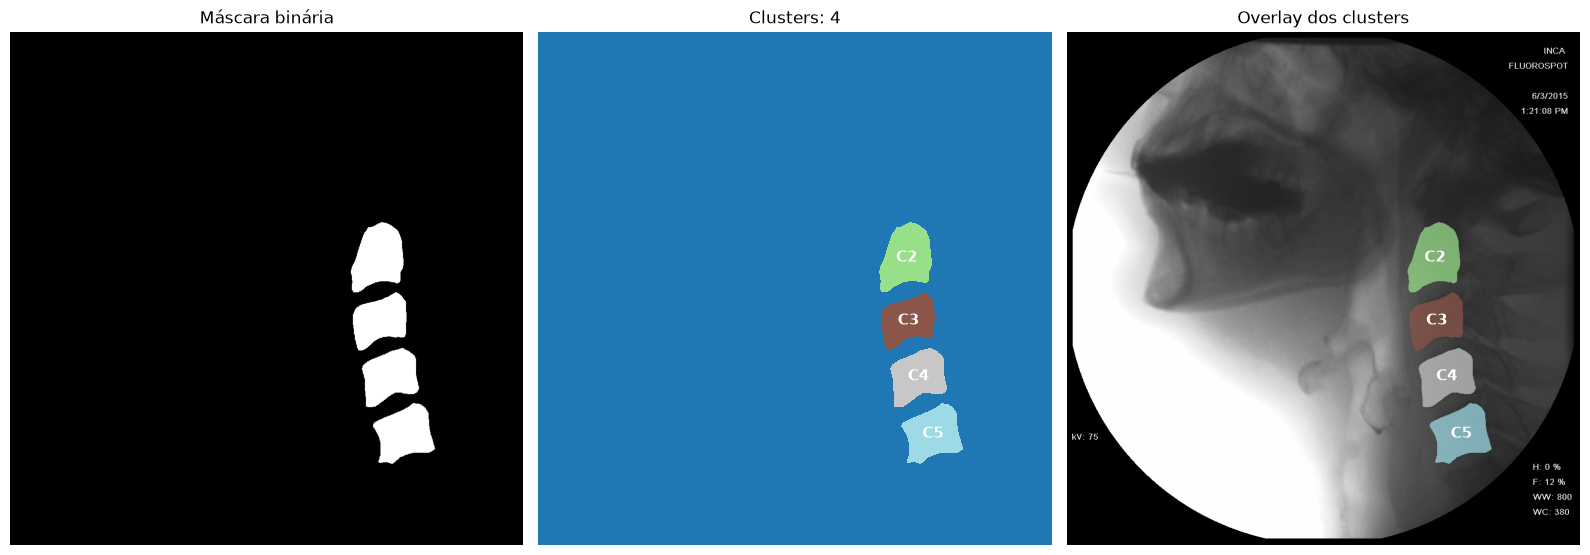

In [ ]:
def label_to_rgba(labels):
    labels = np.asarray(labels)
    cmap = plt.get_cmap("tab20", int(labels.max()) + 1)
    rgba = cmap(labels)
    rgba[..., 3] = np.where(labels > 0, 0.75, 0.0)
    return rgba


def plot_clusters(mask, labels, stats, image=None):
    fig, axes = plt.subplots(1, 3 if image is not None else 2, figsize=(16, 6))
    axes = np.atleast_1d(axes)

    axes[0].imshow(mask, cmap="gray")
    axes[0].set_title("Máscara binária")
    axes[0].axis("off")

    axes[1].imshow(labels, cmap="tab20", interpolation="nearest")
    axes[1].set_title(f"Clusters: {int(labels.max())}")
    axes[1].axis("off")

    if image is not None:
        axes[2].imshow(image, cmap="gray")
        axes[2].imshow(label_to_rgba(labels))
        axes[2].set_title("Overlay dos clusters")
        axes[2].axis("off")

    for ax in axes[1:]:
        for _, row in stats.iterrows():
            y = row["centroid_axis0"]
            x = row["centroid_axis1"]
            label = row.get("vertebra", str(int(row["label_id"])))
            ax.text(x, y, label, color="white", fontsize=11, ha="center", va="center", weight="bold")

    plt.tight_layout()


plot_clusters(foreground, vertebra_labels, vertebra_stats, image_display)

## Navegação interativa pelo dataset

Use as setas ou o slider para percorrer as máscaras, o menu `labeler` para restringir a navegação
a um rotulador, e os campos `video_id`/`frame_id` + botão "Buscar" para ir direto a um exemplo
(ex: v62_f64). Se `ipywidgets` não estiver instalado, use `render_dataset_item(indice)`.


In [ ]:
def process_label_path(label_path, image_path=None):
    """Roda a clusterizacao num arquivo e devolve tudo que os plots precisam."""
    foreground_local = to_foreground_mask(load_image(label_path), BINARY_VALUES, FOREGROUND_THRESHOLD)

    image_display_local = None
    if image_path is not None and not pd.isna(image_path) and Path(image_path).exists():
        image_display_local = normalize_image_for_display(load_image(image_path))

    labels_local, stats_local = cluster_vertebrae(foreground_local, CLUSTERING)
    return {
        "label_path": Path(label_path),
        "image_path": None if image_path is None or pd.isna(image_path) else Path(image_path),
        "foreground": foreground_local,
        "image_display": image_display_local,
        "vertebra_labels": labels_local,
        "vertebra_stats": stats_local,
    }


def process_dataset_index(index):
    if mask_index.empty:
        raise ValueError("mask_index está vazio.")
    index = int(np.clip(index, 0, len(mask_index) - 1))
    row = mask_index.iloc[index]
    result = process_label_path(row["label_path"], row["image_path"])
    result["dataset_index"] = index
    result["dataset_row"] = row
    return result


def selected_masks_from_result(result, selected_vertebrae=None):
    """Mascaras individuais por vertebra + a combinada, reusando select_vertebrae do pacote."""
    selected_vertebrae = selected_vertebrae or SELECTED_VERTEBRAE
    labels = result["vertebra_labels"]
    stats = result["vertebra_stats"]

    combined, mapping = select_vertebrae(labels, stats, selected_vertebrae, compact_ids=True)
    masks = {
        row.vertebra: labels == row.source_ordered_id
        for row in mapping.itertuples()
    }
    return masks, combined.astype(np.uint8)


def render_dataset_item(index, show_stats=True):
    result = process_dataset_index(index)
    row = result["dataset_row"]
    print(f"Amostra {index + 1}/{len(mask_index)} | {row['video_frame']} | labeler={row['labeler']}")
    print("label:", result["label_path"])

    plot_clusters(
        result["foreground"],
        result["vertebra_labels"],
        result["vertebra_stats"],
        result["image_display"],
    )
    plt.show()

    selected_masks, combined_selected = selected_masks_from_result(result)
    if selected_masks:
        fig, axes = plt.subplots(1, len(selected_masks) + 1, figsize=(5 * (len(selected_masks) + 1), 5))
        axes = np.atleast_1d(axes).ravel()
        axes[0].imshow(combined_selected, cmap="tab10", interpolation="nearest")
        axes[0].set_title("Selecionadas")
        axes[0].axis("off")
        for ax, (vertebra, mask_i) in zip(axes[1:], selected_masks.items()):
            if result["image_display"] is None:
                ax.imshow(mask_i, cmap="gray")
            else:
                ax.imshow(result["image_display"], cmap="gray")
                ax.imshow(np.ma.masked_where(~mask_i, mask_i), cmap="autumn", alpha=0.55)
            ax.set_title(vertebra)
            ax.axis("off")
        plt.tight_layout()
        plt.show()

    if show_stats:
        display(result["vertebra_stats"])
    return result


In [ ]:
try:
    import ipywidgets as widgets

    if mask_index.empty:
        print("mask_index está vazio; não há dataset para navegar.")
    else:
        output = widgets.Output()
        search_status = widgets.Label(value="")

        labeler_values = sorted(str(v) for v in mask_index["labeler"].dropna().unique())
        labeler_dropdown = widgets.Dropdown(
            options=["todos"] + labeler_values,
            value="todos",
            description="labeler",
            layout=widgets.Layout(width="200px"),
        )

        def get_filtered_positions():
            if labeler_dropdown.value == "todos":
                return mask_index.index.to_numpy()
            return mask_index.index[mask_index["labeler"].astype(str) == labeler_dropdown.value].to_numpy()

        filtered_positions = get_filtered_positions()

        index_slider = widgets.IntSlider(
            value=int(np.clip(CURRENT_INDEX, 0, len(filtered_positions) - 1)),
            min=0,
            max=len(filtered_positions) - 1,
            step=1,
            description="índice",
            continuous_update=False,
            layout=widgets.Layout(width="520px"),
        )
        prev_button = widgets.Button(description="←", layout=widgets.Layout(width="48px"))
        next_button = widgets.Button(description="→", layout=widgets.Layout(width="48px"))

        video_id_box = widgets.Text(value="", description="video_id", placeholder="ex: 62", layout=widgets.Layout(width="160px"))
        frame_id_box = widgets.Text(value="", description="frame_id", placeholder="ex: 64", layout=widgets.Layout(width="160px"))
        search_button = widgets.Button(description="Buscar")

        def redraw(change=None):
            with output:
                clear_output(wait=True)
                render_dataset_item(int(filtered_positions[index_slider.value]))

        def go_previous(_):
            index_slider.value = max(index_slider.min, index_slider.value - 1)

        def go_next(_):
            index_slider.value = min(index_slider.max, index_slider.value + 1)

        def on_labeler_change(change):
            global filtered_positions
            filtered_positions = get_filtered_positions()
            search_status.value = ""
            if len(filtered_positions) == 0:
                index_slider.min = index_slider.max = 0
                with output:
                    clear_output(wait=True)
                    print(f"Nenhuma máscara para labeler={labeler_dropdown.value!r}.")
                return
            index_slider.max = len(filtered_positions) - 1
            if index_slider.value > index_slider.max:
                index_slider.value = index_slider.max
            else:
                redraw()

        def on_search_click(_):
            try:
                video_id = int(video_id_box.value.strip())
                frame_id = int(frame_id_box.value.strip())
            except ValueError:
                search_status.value = "Informe video_id e frame_id inteiros."
                return

            candidates = mask_index.loc[filtered_positions]
            match = candidates[(candidates["video_id"] == video_id) & (candidates["frame_id"] == frame_id)]
            if match.empty:
                search_status.value = f"Não encontrado: v{video_id}_f{frame_id}."
                return

            slider_position = int(np.where(filtered_positions == int(match.index[0]))[0][0])
            search_status.value = f"Encontrado em índice {slider_position}."
            if index_slider.value == slider_position:
                redraw()
            else:
                index_slider.value = slider_position

        prev_button.on_click(go_previous)
        next_button.on_click(go_next)
        search_button.on_click(on_search_click)
        labeler_dropdown.observe(on_labeler_change, names="value")
        index_slider.observe(redraw, names="value")

        display(widgets.HBox([labeler_dropdown, prev_button, next_button, index_slider]))
        display(widgets.HBox([video_id_box, frame_id_box, search_button, search_status]))
        display(output)
        redraw()
except ImportError:
    print("ipywidgets não está instalado neste kernel.")
    print("Use render_dataset_item(0), render_dataset_item(1), ... para navegar manualmente.")


Output()

### Casos problemáticos

A lista de "casos ruins" que ficava aqui à mão foi substituída pelo manifesto que o pipeline
gera (`targets/<modalidade>/variants_manifest.csv`). Ordene por `area_ratio_max_min` em ordem
decrescente: quando duas vértebras se fundem, um cluster fica com o dobro da área dos demais.
Numa validação contra os 11 frames catalogados manualmente, 8 apareceram no top 16 de 809.
Veja a seção "Exploração da área dos clusters" abaixo.


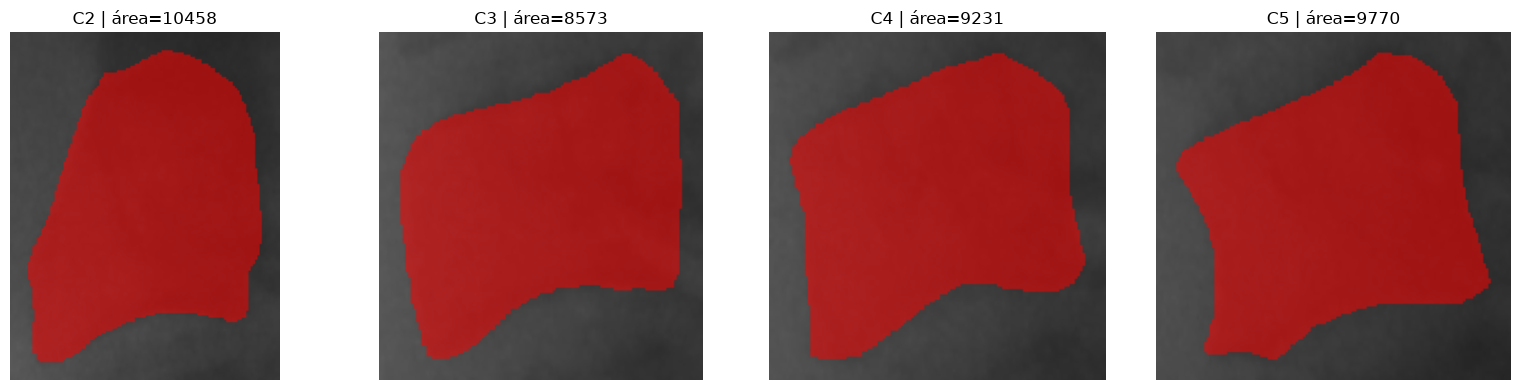

In [ ]:
def crop_with_padding(mask, pad=8):
    coords = np.argwhere(mask)
    if coords.size == 0:
        return mask, (slice(0, mask.shape[0]), slice(0, mask.shape[1]))
    y0, x0 = coords.min(axis=0)
    y1, x1 = coords.max(axis=0) + 1
    y0 = max(0, y0 - pad)
    x0 = max(0, x0 - pad)
    y1 = min(mask.shape[0], y1 + pad)
    x1 = min(mask.shape[1], x1 + pad)
    slices = (slice(y0, y1), slice(x0, x1))
    return mask[slices], slices


n = int(vertebra_labels.max())
cols = min(4, max(1, n))
rows = int(np.ceil(n / cols))
fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 4 * rows))
axes = np.atleast_1d(axes).ravel()

for idx in range(1, n + 1):
    ax = axes[idx - 1]
    row = vertebra_stats.loc[vertebra_stats["ordered_id"] == idx].iloc[0]
    mask_i = vertebra_labels == idx
    cropped, slices = crop_with_padding(mask_i)
    if image_display is None:
        ax.imshow(cropped, cmap="gray")
    else:
        ax.imshow(image_display[slices], cmap="gray")
        ax.imshow(np.ma.masked_where(~cropped, cropped), cmap="autumn", alpha=0.55)
    ax.set_title(f"{row['vertebra']} | área={int(row['area'])}")
    ax.axis("off")

for ax in axes[n:]:
    ax.axis("off")

plt.tight_layout()

## Separar apenas C2 e C4

Esta seção cria máscaras binárias separadas para as vértebras em `SELECTED_VERTEBRAE`. Se C2 ou C4 parecerem trocadas, ajuste `ORDER_HIGH_TO_LOW` ou `ANATOMICAL_AXIS` e rode novamente a partir da seção de separação.

Máscaras selecionadas: ['C2', 'C3', 'C4']


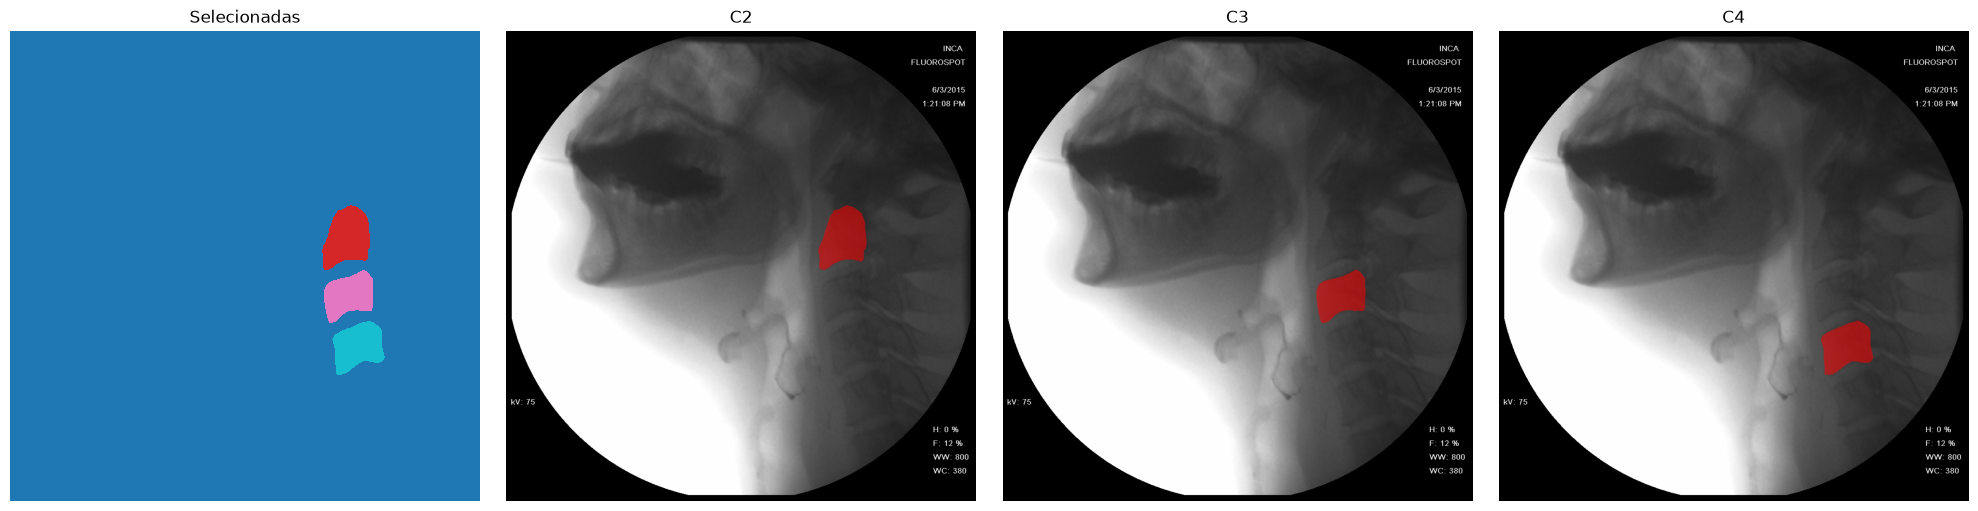

In [ ]:
name_to_id = dict(zip(vertebra_stats["vertebra"], vertebra_stats["ordered_id"]))
selected_masks = {}

for vertebra in SELECTED_VERTEBRAE:
    if vertebra not in name_to_id:
        print(f"{vertebra}: não encontrada. Disponíveis: {sorted(name_to_id)}")
        continue
    selected_masks[vertebra] = vertebra_labels == int(name_to_id[vertebra])

combined_selected_mask = np.zeros_like(vertebra_labels, dtype=np.uint8)
for idx, vertebra in enumerate(selected_masks, start=1):
    combined_selected_mask[selected_masks[vertebra]] = idx

print("Máscaras selecionadas:", list(selected_masks))

fig, axes = plt.subplots(1, max(1, len(selected_masks)) + 1, figsize=(5 * (len(selected_masks) + 1), 5))
axes = np.atleast_1d(axes).ravel()

axes[0].imshow(combined_selected_mask, cmap="tab10", interpolation="nearest")
axes[0].set_title("Selecionadas")
axes[0].axis("off")

for ax, (vertebra, mask_i) in zip(axes[1:], selected_masks.items()):
    if image_display is None:
        ax.imshow(mask_i, cmap="gray")
    else:
        ax.imshow(image_display, cmap="gray")
        ax.imshow(np.ma.masked_where(~mask_i, mask_i), cmap="autumn", alpha=0.55)
    ax.set_title(vertebra)
    ax.axis("off")

plt.tight_layout()

## Exploração da área dos clusters

Lê o manifesto gerado pelo pipeline e usa `area_ratio_max_min` para achar máscaras quebradas,
componentes espúrios ou vértebras agrupadas indevidamente — sem reprocessar o dataset inteiro.


In [ ]:
# AREA_RATIO_THRESHOLD vem da config (target_variants.params.area_ratio_threshold).
manifest_path = Path(targets_dir(str(DATASET_ROOT.parent), DATASET_ROOT.name, TARGET_TYPE)) / MANIFEST_FILENAME
if not manifest_path.exists():
    raise FileNotFoundError(
        f"Manifesto não encontrado em {manifest_path}. "
        f"Rode: python tasks/create_video_frame_dataset.py --config {CONFIG.path}"
    )

manifest = pd.read_csv(manifest_path)
print(f"{len(manifest)} frames no manifesto: {manifest_path}")
display(manifest.head())


961 frames no manifesto: /Users/caioseda/Documents/Trabalho/Tecgraf/projetos/dados_inca/dataset/targets/mask/variants_manifest.csv


,video_frame,selected_labeler,base_path,mask_source,n_clusters,foreground_area,min_cluster_area,max_cluster_area,median_cluster_area,area_ratio_max_min,vertebrae_found,missing_vertebrae
0,v100_f10,VC,targets/mask/raw/VC/v100_f10.tif,base,4,38032,8573,10458,9500.5,1.219876,"C2,C3,C4,C5",NaN
1,v100_f12,AM,targets/mask/raw/AM/v100_f12.tif,base,4,38612,8229,11359,9512.0,1.380362,"C2,C3,C4,C5",NaN
2,v100_f13,BB,targets/mask/raw/BB/v100_f13.tif,base,4,34858,7551,10092,8607.5,1.336512,"C2,C3,C4,C5",NaN
3,v100_f14,BB,targets/mask/raw/BB/v100_f14.tif,base,4,35320,7903,10245,8586.0,1.296343,"C2,C3,C4,C5",NaN
4,v100_f15,VC,targets/mask/raw/VC/v100_f15.tif,base,4,37438,8149,10305,9492.0,1.264572,"C2,C3,C4,C5",NaN


In [ ]:
suspeitos = manifest.sort_values("area_ratio_max_min", ascending=False)
print(f"{(manifest.area_ratio_max_min >= AREA_RATIO_THRESHOLD).sum()} frames acima do limiar {AREA_RATIO_THRESHOLD}")
display(suspeitos.head(20)[[
    "video_frame", "selected_labeler", "n_clusters", "foreground_area",
    "min_cluster_area", "max_cluster_area", "area_ratio_max_min", "vertebrae_found",
]])


25 frames acima do limiar 2.0


,video_frame,selected_labeler,n_clusters,foreground_area,min_cluster_area,max_cluster_area,area_ratio_max_min,vertebrae_found
360,v172_f41,VR,6,29352,3698,10092,2.729043,"C2,C3,C4,C5,C6,C7"
901,v86_f111,CS,4,5335,900,2163,2.403333,"C2,C3,C4,C5"
284,v155_f234,VR,7,38770,3894,9046,2.323061,"C2,C3,C4,C5,C6,C7,C8"
378,v177_f31,VR,5,23028,3509,7811,2.225990,"C2,C3,C4,C5,C6"
277,v154_f135,BB,7,35499,3406,7557,2.218732,"C2,C3,C4,C5,C6,C7,C8"
363,v173_f48,BB,5,26303,3711,8163,2.199677,"C2,C3,C4,C5,C6"
721,v43_f3,CS,5,4836,625,1373,2.196800,"C2,C3,C4,C5,C6"
687,v35_f88,AM,4,16067,2883,6323,2.193202,"C2,C3,C4,C5"
292,v157_f187,CS,5,32603,4589,9916,2.160819,"C2,C3,C4,C5,C6"
568,v221_f41,CS,5,48037,6410,13725,2.141186,"C2,C3,C4,C5,C6"


In [ ]:
def manifest_summary(manifest_df):
    """Distribuicao de clusters e de area, para calibrar min_component_pixels e o limiar."""
    print("Distribuição de n_clusters")
    display(manifest_df.n_clusters.value_counts().sort_index().to_frame("frames"))

    print("Estatísticas de área")
    display(manifest_df[[
        "foreground_area", "min_cluster_area", "max_cluster_area",
        "median_cluster_area", "area_ratio_max_min",
    ]].describe())

    if manifest_df.missing_vertebrae.notna().any():
        print("Frames sem alguma vértebra pedida")
        display(manifest_df[manifest_df.missing_vertebrae.notna()])
    else:
        print("Nenhum frame com vértebra pedida ausente.")


manifest_summary(manifest)


Distribuição de n_clusters


,frames
n_clusters,
3,67
4,366
5,329
6,181
7,18


Estatísticas de área


,foreground_area,min_cluster_area,max_cluster_area,median_cluster_area,area_ratio_max_min
count,961.000000,961.000000,961.000000,961.000000,961.000000
mean,22268.454735,4071.513007,6048.132154,4513.184703,1.494690
std,9011.992727,1532.237733,2360.247241,1702.726867,0.214586
min,3417.000000,625.000000,1006.000000,775.000000,1.035046
25%,17300.000000,3447.000000,5086.000000,3803.000000,1.339190
50%,22470.000000,4024.000000,5977.000000,4436.500000,1.478601
75%,26286.000000,4680.000000,6941.000000,5199.500000,1.606938
max,56596.000000,9677.000000,15518.000000,10237.000000,2.729043


Nenhum frame com vértebra pedida ausente.


In [ ]:
def plot_worst_by_area_ratio(manifest_df, top_n=6):
    """Renderiza os frames mais suspeitos para inspecao visual."""
    worst = manifest_df.nlargest(top_n, "area_ratio_max_min")
    positions = mask_index[mask_index.video_frame.isin(worst.video_frame)].index.tolist()

    rendered = []
    for pos in positions[:top_n]:
        print("=" * 100)
        rendered.append(render_dataset_item(pos, show_stats=True))
    return rendered


# piores = plot_worst_by_area_ratio(manifest, top_n=6)


## Revisão interativa: marcar frames com vértebras fundidas

Navega pelos frames mais suspeitos do manifesto e compara, lado a lado, os métodos **do frame
inteiro** (`connected_components`, `watershed` experimental, `axis_kmeans`) — nunca misturados
dentro de um mesmo frame.

Quando a fusão é real, nenhum método a desfaz: a máscara precisa ser editada à mão. Os
controles abaixo servem a isso:

- **ordenar por / rank / ← →** — percorre o manifesto pela coluna escolhida (o padrão,
  `area_ratio_max_min`, é o melhor proxy que temos para achar fusões).
- **video_frame + Ir** — vai direto a um exemplo pelo id (`v62_f64`), sem depender do rank
  (que muda a cada reordenação).
- **folga (px) / altura** — zoom: `folga` recorta mais perto da máscara, `altura` estica os
  painéis. A roda do mouse continua dando zoom dentro do painel.
- **⚠ marcar erro** — põe o frame na fila de revisão
  (o CSV de `fixed_masks.review_queue_path` da config escolhida, gravado na hora). A decisão é **sempre
  manual**: `area_ratio_max_min` alto também acontece quando uma vértebra é naturalmente
  maior que as vizinhas, e só olhando dá para separar os dois casos.

A fila é consumida na etapa seguinte, pelo editor napari.

In [ ]:
# Navega pelos frames mais suspeitos do manifesto (por qualquer coluna numerica), compara os
# METODOS DO FRAME INTEIRO (connected_components x watershed) lado a lado -- nao ha mais split
# local de um componente -- e permite MARCAR a mao os frames em que duas vertebras foram
# fundidas numa so.
#
# A marcacao NUNCA e automatica: `area_ratio_max_min` serve apenas para ordenar os candidatos,
# porque algumas vertebras sao naturalmente maiores que as vizinhas e so o olho distingue esse
# caso de uma fusao real. Os frames marcados vao para a fila de revisao (CSV), consumida por
#
#     python tasks/fix_masks.py --config <CONFIG_NAME>
#
# que abre um a um no napari para editar a mascara com pincel/borracha.

from vfss_data_split.target.mask_fixes import (
    flag_frame,
    has_fixed_mask,
    is_flagged,
    load_queue,
    queue_summary,
    save_queue,
    unflag_frame,
)

MANIFEST_SORT_COLUMN = "area_ratio_max_min"
MANIFEST_SORT_ASCENDING = False
COMPARE_METHODS = ["connected_components", "watershed"]  # sempre frame inteiro, nunca misturados

# REVIEW_QUEUE_PATH e FIXES_DIR vem da config escolhida na celula de parametros -- cada dataset
# (INCA, UNM) tem a sua fila e a sua pasta de correcoes.

CROP_PAD = 12        # folga em px ao redor da mascara: menor = mais zoom
PANEL_HEIGHT = 720   # altura dos paineis em px


def cut_length(lab, mask):
    """Pares de pixels vizinhos (dentro da mascara) atribuidos a clusters diferentes.
    Corte baixo = fronteira passa por um "pescoco" estreito; corte alto = atravessa a vertebra."""
    total = 0
    for a, b in [((slice(None, -1), slice(None)), (slice(1, None), slice(None))),
                 ((slice(None), slice(None, -1)), (slice(None), slice(1, None)))]:
        both = mask[a] & mask[b]
        total += int((both & (lab[a] != lab[b])).sum())
    return total


def _ratio(lab):
    a = component_stats(lab).area
    return (a.max() / max(a.min(), 1)) if len(a) else float("nan")


def crop_to_mask(mask, *labs, pad=CROP_PAD):
    coords = np.argwhere(mask)
    y0, x0 = coords.min(0); y1, x1 = coords.max(0) + 1
    s = (slice(max(0, y0 - pad), y1 + pad), slice(max(0, x0 - pad), x1 + pad))
    return [l[s] for l in labs]


def build_panels_figure(panels, mask, frame_title, panel_height=PANEL_HEIGHT, pad=CROP_PAD):
    """Grade de heatmaps Plotly (zoom/pan nativos) reproduzindo o cmap='tab10' discreto usado
    antes com matplotlib. `pad` controla o recorte ao redor da mascara -- e o zoom "de entrada",
    complementar ao zoom da roda do mouse, que so aumenta o que ja esta no painel.

    `panels` sao pares `(titulo, labels)` ou triplas `(titulo, labels, mascara_do_painel)`. A
    tripla serve quando os paineis comparam mascaras DIFERENTES (base x corrigida): `corte` passa
    a ser medido contra a mascara de cada painel. O recorte usa sempre `mask`, para os paineis
    ficarem alinhados e a comparacao ser pixel a pixel."""
    import plotly.graph_objects as go
    from plotly.subplots import make_subplots
    from matplotlib.colors import Normalize, to_hex

    cmap = plt.get_cmap("tab10")
    norm = Normalize(vmin=0, vmax=10)
    palette = [to_hex(cmap(norm(v))) for v in range(11)]
    colorscale = [[v / 10, palette[v]] for v in range(11)]

    normalized = [(p[0], p[1], p[2] if len(p) > 2 else mask) for p in panels]
    cropped = crop_to_mask(mask, *[lab for _, lab, _ in normalized], pad=pad)
    n = len(normalized)
    subplot_titles = [
        f"{title}<br>{int(lab.max())} clusters | corte={cut_length(lab, panel_mask)} | ratio={_ratio(lab):.1f}"
        for title, lab, panel_mask in normalized
    ]

    fig = make_subplots(rows=1, cols=n, subplot_titles=subplot_titles, horizontal_spacing=0.03)
    for i, ((_, lab, _), clab) in enumerate(zip(normalized, cropped), start=1):
        fig.add_trace(
            go.Heatmap(
                z=clab, colorscale=colorscale, zmin=0, zmax=10, showscale=False,
                # zsmooth=False: sem isso, o Heatmap trata a matriz como "imagem" e
                # interpola/borra cores entre pixels vizinhos de clusters diferentes (inclusive
                # na fronteira com o fundo) -- exatamente o oposto do que queremos para rotulos
                # discretos. Equivalente ao interpolation="nearest" do matplotlib de antes.
                zsmooth=False,
                hovertemplate="linha=%{y}<br>coluna=%{x}<br>cluster=%{z}<extra></extra>",
            ),
            row=1, col=i,
        )
        xaxis_id = "x" if i == 1 else f"x{i}"
        fig.update_xaxes(visible=False, row=1, col=i)
        fig.update_yaxes(visible=False, autorange="reversed", scaleanchor=xaxis_id,
                         scaleratio=1, row=1, col=i)

    fig.update_layout(
        title=frame_title,
        height=panel_height,
        # Sem width fixo: um valor fixo (ex. 520px * 3 paineis = 1560px) fica mais largo que o
        # container do notebook e o excesso e cortado (nao rola) em vez de aparecer. autosize +
        # responsive fazem a figura preencher a largura disponivel, entao os N paineis sempre
        # cabem por inteiro.
        autosize=True,
        margin=dict(l=10, r=10, t=90, b=10),
        dragmode="pan",
    )
    return fig


def preview_frame_methods(dataset_index, methods=None, panel_height=PANEL_HEIGHT, pad=CROP_PAD):
    """Sem ipywidgets: chame manualmente, ex. preview_frame_methods(12).

    Roda cada metodo em `methods` no frame INTEIRO (nunca misturados) e mostra lado a lado.
    """
    methods = methods or COMPARE_METHODS
    row = mask_index.iloc[int(np.clip(dataset_index, 0, len(mask_index) - 1))]
    mask = to_foreground_mask(load_image(row["label_path"]), BINARY_VALUES, FOREGROUND_THRESHOLD)

    panels = []
    for method in methods:
        params = ClusteringParams(**{**CLUSTERING.__dict__, "method": method})
        labels, _ = cluster_vertebrae(mask, params)
        label = method + (" (experimental)" if method == "watershed" else "")
        panels.append((label, labels))

    fig = build_panels_figure(panels, mask, frame_title=row["video_frame"],
                              panel_height=panel_height, pad=pad)
    fig.show(config={"scrollZoom": True, "displaylogo": False, "responsive": True})
    return {method: lab for method, (_, lab) in zip(methods, panels)}


def build_manifest_walk(sort_column=None, ascending=None):
    """Manifesto ordenado + posicoes correspondentes em mask_index."""
    sort_column = sort_column or MANIFEST_SORT_COLUMN
    ascending = MANIFEST_SORT_ASCENDING if ascending is None else ascending
    if sort_column not in manifest.columns:
        raise KeyError(f"{sort_column!r} nao esta no manifesto. Colunas: {list(manifest.columns)}")

    position_by_frame = {vf: pos for pos, vf in enumerate(mask_index["video_frame"])}
    ordered = (
        manifest[manifest["video_frame"].isin(position_by_frame)]
        .sort_values(sort_column, ascending=ascending, kind="stable")
        .reset_index(drop=True)
    )
    positions = [position_by_frame[vf] for vf in ordered["video_frame"]]
    return ordered, positions


manifest_ordered, manifest_positions = build_manifest_walk()
print(f"{len(manifest_positions)} frames ordenados por {MANIFEST_SORT_COLUMN} "
     f"({'crescente' if MANIFEST_SORT_ASCENDING else 'decrescente'}). "
     f"{(manifest.area_ratio_max_min >= AREA_RATIO_THRESHOLD).sum()} frames com "
     f"area_ratio_max_min >= {AREA_RATIO_THRESHOLD}.")

# Fila de revisao: e reescrita a cada marcacao, entao fechar o notebook nao perde nada.
review_queue = load_queue(str(REVIEW_QUEUE_PATH))
print(f"Fila de revisao ({REVIEW_QUEUE_PATH}): {queue_summary(review_queue, str(FIXES_DIR))}.")


def rank_of_video_frame(video_frame):
    """Rank (posicao na ordenacao atual) de um `video_frame`, ou None se nao estiver la."""
    matches = manifest_ordered.index[manifest_ordered["video_frame"].astype(str) == str(video_frame).strip()]
    return int(matches[0]) if len(matches) else None


def render_rank(rank, methods=None, panel_height=PANEL_HEIGHT, pad=CROP_PAD):
    """Mostra o frame daquele rank no manifesto ordenado + comparacao entre metodos.

    Devolve a linha do manifesto, para quem chama saber qual (video_frame, labeler) esta na tela.
    """
    if not manifest_positions:
        print("Nenhum frame do manifesto esta em mask_index."); return None
    rank = int(np.clip(rank, 0, len(manifest_positions) - 1))
    row = manifest_ordered.iloc[rank]
    position = int(manifest_positions[rank])
    print(f"Rank {rank + 1}/{len(manifest_ordered)} | {row['video_frame']} | "
         f"labeler={row['selected_labeler']}")
    print(f"  n_clusters={row['n_clusters']} | area_ratio_max_min={row['area_ratio_max_min']:.2f} | "
         f"vertebrae_found={row['vertebrae_found']} | missing_vertebrae={row.get('missing_vertebrae', '')}")
    if "mask_source" in row.index and str(row["mask_source"]) == "fixed":
        print("  [fixed_masks] este frame ja foi gerado a partir de uma mascara corrigida a mao.")
    preview_frame_methods(position, methods=methods, panel_height=panel_height, pad=pad)
    return row


try:
    import ipywidgets as widgets

    numeric_columns = [c for c in manifest.columns if pd.api.types.is_numeric_dtype(manifest[c])]
    sort_column_dropdown = widgets.Dropdown(
        options=numeric_columns,
        value=MANIFEST_SORT_COLUMN if MANIFEST_SORT_COLUMN in numeric_columns else numeric_columns[0],
        description="ordenar por", style={"description_width": "initial"}, layout=widgets.Layout(width="300px"),
    )
    ascending_toggle = widgets.ToggleButton(value=MANIFEST_SORT_ASCENDING, description="crescente",
                                           layout=widgets.Layout(width="110px"))
    rank_slider = widgets.IntSlider(value=0, min=0, max=max(len(manifest_positions) - 1, 0), step=1,
                                    description="rank", continuous_update=False, layout=widgets.Layout(width="420px"))
    prev_button = widgets.Button(description="←", layout=widgets.Layout(width="48px"))
    next_button = widgets.Button(description="→", layout=widgets.Layout(width="48px"))

    methods_select = widgets.SelectMultiple(
        options=["connected_components", "watershed", "axis_kmeans"],
        value=tuple(COMPARE_METHODS),
        description="metodos", rows=3, layout=widgets.Layout(width="260px"),
    )

    # --- Ir direto a um video_frame (o rank muda a cada reordenacao; o id nao) ---
    frame_box = widgets.Text(value="", description="video_frame", placeholder="ex: v62_f64",
                             style={"description_width": "initial"}, layout=widgets.Layout(width="260px"))
    frame_button = widgets.Button(description="Ir", layout=widgets.Layout(width="48px"))
    frame_status = widgets.Label(value="")

    # --- Zoom: `pad` recorta ao redor da mascara, `altura` estica os paineis ---
    pad_slider = widgets.IntSlider(value=CROP_PAD, min=0, max=120, step=4, description="folga (px)",
                                   continuous_update=False, style={"description_width": "initial"},
                                   layout=widgets.Layout(width="300px"))
    height_slider = widgets.IntSlider(value=PANEL_HEIGHT, min=360, max=1400, step=40, description="altura",
                                      continuous_update=False, style={"description_width": "initial"},
                                      layout=widgets.Layout(width="300px"))

    # --- Marcacao manual de erro ---
    flag_toggle = widgets.ToggleButton(value=False, description="⚠ marcar erro",
                                       tooltip="Marca este frame como vertebras fundidas, para corrigir no napari",
                                       layout=widgets.Layout(width="150px"))
    flag_reason = widgets.Text(value="vertebras fundidas", description="motivo",
                               style={"description_width": "initial"}, layout=widgets.Layout(width="320px"))
    flag_status = widgets.Label(value="")

    review_output = widgets.Output()
    _current_row = {"video_frame": None, "selected_labeler": None}
    _suppress_toggle = {"on": False}

    def _refresh_flag_status():
        flagged = len(review_queue)
        pend = queue_summary(review_queue, str(FIXES_DIR))
        vf, lb = _current_row["video_frame"], _current_row["selected_labeler"]
        aqui = ""
        if vf is not None and has_fixed_mask(str(FIXES_DIR), lb, vf):
            aqui = " · este frame ja tem mascara corrigida em disco"
        flag_status.value = f"{pend}{aqui}" if flagged else f"fila vazia{aqui}"

    def _sync_toggle():
        """Reflete no botao se o frame na tela ja esta na fila (sem disparar o handler)."""
        vf, lb = _current_row["video_frame"], _current_row["selected_labeler"]
        _suppress_toggle["on"] = True
        try:
            flag_toggle.value = bool(vf is not None and is_flagged(review_queue, vf, lb))
        finally:
            _suppress_toggle["on"] = False
        flag_toggle.button_style = "danger" if flag_toggle.value else ""
        flag_toggle.description = "⚠ marcado" if flag_toggle.value else "⚠ marcar erro"
        _refresh_flag_status()

    def _on_flag(change):
        global review_queue
        if _suppress_toggle["on"]:
            return
        vf, lb = _current_row["video_frame"], _current_row["selected_labeler"]
        if vf is None:
            return
        if change["new"]:
            row = manifest_ordered.iloc[rank_slider.value]
            review_queue = flag_frame(
                review_queue, vf, lb,
                motivo=flag_reason.value.strip() or "vertebras fundidas",
                area_ratio_max_min=row.get("area_ratio_max_min"),
            )
        else:
            review_queue = unflag_frame(review_queue, vf, lb)
        save_queue(review_queue, str(REVIEW_QUEUE_PATH))
        _sync_toggle()

    def _redraw(change=None):
        with review_output:
            clear_output(wait=True)
            row = render_rank(rank_slider.value, methods=list(methods_select.value) or COMPARE_METHODS,
                              panel_height=height_slider.value, pad=pad_slider.value)
        if row is not None:
            _current_row["video_frame"] = str(row["video_frame"])
            _current_row["selected_labeler"] = str(row["selected_labeler"])
        _sync_toggle()

    def _resort(change=None):
        global manifest_ordered, manifest_positions
        manifest_ordered, manifest_positions = build_manifest_walk(
            sort_column_dropdown.value, ascending_toggle.value
        )
        rank_slider.max = max(len(manifest_positions) - 1, 0)
        if rank_slider.value > rank_slider.max:
            rank_slider.value = rank_slider.max
        else:
            _redraw()

    def _on_goto_frame(_=None):
        rank = rank_of_video_frame(frame_box.value)
        if rank is None:
            frame_status.value = f"{frame_box.value.strip()!r} nao esta no manifesto."
            return
        frame_status.value = f"rank {rank + 1}"
        if rank_slider.value == rank:
            _redraw()
        else:
            rank_slider.value = rank

    prev_button.on_click(lambda _: setattr(rank_slider, "value", max(rank_slider.min, rank_slider.value - 1)))
    next_button.on_click(lambda _: setattr(rank_slider, "value", min(rank_slider.max, rank_slider.value + 1)))
    rank_slider.observe(_redraw, names="value")
    sort_column_dropdown.observe(_resort, names="value")
    ascending_toggle.observe(_resort, names="value")
    methods_select.observe(_redraw, names="value")
    pad_slider.observe(_redraw, names="value")
    height_slider.observe(_redraw, names="value")
    frame_button.on_click(_on_goto_frame)
    flag_toggle.observe(_on_flag, names="value")

    display(widgets.HBox([sort_column_dropdown, ascending_toggle, prev_button, next_button, rank_slider]))
    display(widgets.HBox([frame_box, frame_button, frame_status]))
    display(widgets.HBox([methods_select, widgets.VBox([pad_slider, height_slider])]))
    display(widgets.HBox([flag_toggle, flag_reason]))
    display(flag_status)
    display(review_output)
    _redraw()
except ImportError:
    print("ipywidgets nao esta instalado neste kernel. Navegue manualmente, ex:")
    print("  render_rank(0, methods=['connected_components', 'watershed'], pad=4)")
    print("E marque a mao:")
    print("  review_queue = flag_frame(review_queue, 'v62_f64', 'VC', motivo='vertebras fundidas')")
    print("  save_queue(review_queue, str(REVIEW_QUEUE_PATH))")


961 frames ordenados por area_ratio_max_min (decrescente). 25 frames com area_ratio_max_min >= 2.0.
Fila de revisao (/Users/caioseda/Documents/Trabalho/Tecgraf/projetos/vfss-data-split/data/metadados/inca-mascaras-para-corrigir.csv): 11 frames na fila, 0 pendentes de correção.


Label(value='')

Output()

## Correção das máscaras marcadas (napari)

Os frames marcados acima entram na fila de revisão. Para consertá-los, o caminho normal é o
script — abre uma janela napari com o frame, a máscara sobreposta e pincel/borracha, e salva
em `data/mascaras-corrigidas/<labeler>/<video_frame>.tif`:

```bash
uv pip install -e '.[edit]'          # napari é dependência opcional
python tasks/fix_masks.py --config inca-vfss   # ou unm-vfss
```

> **Se o kernel morrer ao abrir o napari**, o binding Qt está quebrado — não é o notebook.
> Confira com `python -c "import napari; napari.Viewer(show=False); print('Qt OK')"` num
> terminal: se falhar ali também, veja a nota sobre PyQt6 no README. O caminho pelo
> terminal (`tasks/fix_masks.py`) é o suportado; a célula abaixo é conveniência.

Atalhos: `S` salvar e avançar · `A`/`D` anterior/próximo · `W`/`E` pincel/borracha ·
`⇧Z` voltar ao original · `⇧C` zoom na máscara · `⇧D` pular sem salvar.

Depois de corrigir, rode o pipeline de novo: com
`target_variants.params.fixed_masks.enabled: true` no YAML, a clusterização usa a máscara
corrigida no lugar da base, o log diz `[fixed_masks] ATIVO — N máscaras corrigidas
disponíveis` e o manifesto marca esses frames com `mask_source='fixed'`.

A célula abaixo abre o mesmo editor a partir do notebook (útil para uma sessão curta logo
depois de marcar); deixe `RUN_EDITOR = False` para não abrir janela ao rodar tudo.

In [ ]:
RUN_EDITOR = False  # True abre a janela napari para os frames pendentes da fila.

if RUN_EDITOR:
    from vfss_data_split.target.mask_editor import run_mask_editor

    editor = run_mask_editor(
        queue_path=str(REVIEW_QUEUE_PATH),
        dataset_root=str(DATASET_ROOT),
        fixes_dir=str(FIXES_DIR),
        target_type=TARGET_TYPE,
        base_variant=BASE_VARIANT,
        only_pending=True,   # False revisita tambem o que ja foi corrigido
        limit=None,
    )
else:
    print("RUN_EDITOR=False. Caminho normal:")
    print(f"  python tasks/fix_masks.py --config {CONFIG_NAME}")
    print(f"Fila: {REVIEW_QUEUE_PATH} — {queue_summary(review_queue, str(FIXES_DIR))}")


Nada a corrigir: 11 frames na fila, 0 pendentes de correção.
Fila: /Users/caioseda/Documents/Trabalho/Tecgraf/projetos/vfss-data-split/data/metadados/inca-mascaras-para-corrigir.csv


## Validação das correções: base × corrigida

Mesma navegação da célula de revisão — ordenada por `area_ratio_max_min` — mas agora cada frame
aparece **duas vezes**: à esquerda a clusterização da máscara base, à direita a da máscara
corrigida lida da pasta `fixed_masks.dir` da config escolhida. É assim que se confere se o conserto no napari de
fato separou as vértebras, clusterizando as duas na hora, **sem precisar rodar o pipeline de
novo**.

- **só os corrigidos** — desmarque para percorrer o dataset inteiro (frames sem correção
  aparecem só com o painel da base).
- O que olhar: `n_clusters` maior depois do conserto significa que a fusão foi desfeita; `ratio`
  menor reforça. Se o número de clusters não mudou, o conserto não pegou — reabra o frame no
  napari (`python tasks/fix_masks.py --config <CONFIG_NAME> --all`).
- `fixes_report()` devolve a mesma comparação em tabela, para todas as correções de uma vez.

In [ ]:
# Valida as correcoes: percorre o dataset ordenado por `area_ratio_max_min` (a mesma navegacao da
# celula de revisao) e mostra, lado a lado, a clusterizacao da mascara BASE e a da mascara
# CORRIGIDA lida de FIXES_DIR. E aqui que se confere se o conserto no napari de fato separou as
# vertebras -- clusterizando as duas na hora, sem precisar rodar o pipeline de novo.

from vfss_data_split.target.mask_fixes import has_fixed_mask, load_fixed_mask

VALIDATION_SORT_COLUMN = "area_ratio_max_min"
VALIDATION_ASCENDING = False
VALIDATION_ONLY_FIXED = True   # False percorre o dataset inteiro, tenha correcao ou nao


def masks_for_row(row):
    """(mascara base, mascara corrigida ou None) para uma linha de `mask_index`."""
    base = to_foreground_mask(load_image(row["label_path"]), BINARY_VALUES, FOREGROUND_THRESHOLD)
    fixed_raw = load_fixed_mask(str(FIXES_DIR), row["labeler"], row["video_frame"])
    fixed = (None if fixed_raw is None
             else to_foreground_mask(fixed_raw, BINARY_VALUES, FOREGROUND_THRESHOLD))
    return base, fixed


def cluster_summary(mask):
    """(labels, n_clusters, area_ratio) da mascara com o CLUSTERING atual."""
    if mask is None:
        return None, np.nan, np.nan
    labels, stats = cluster_vertebrae(mask, CLUSTERING)
    return labels, len(stats), _ratio(labels)


def build_validation_walk(only_fixed=None, sort_column=None, ascending=None):
    """Manifesto ordenado (com a marca `tem_correcao`) + posicoes em `mask_index`."""
    only_fixed = VALIDATION_ONLY_FIXED if only_fixed is None else only_fixed
    sort_column = sort_column or VALIDATION_SORT_COLUMN
    ascending = VALIDATION_ASCENDING if ascending is None else ascending

    position_by_frame = {vf: pos for pos, vf in enumerate(mask_index["video_frame"])}
    walk = manifest[manifest["video_frame"].isin(position_by_frame)].copy()
    walk["tem_correcao"] = [
        has_fixed_mask(str(FIXES_DIR), labeler, video_frame)
        for video_frame, labeler in zip(walk["video_frame"], walk["selected_labeler"])
    ]
    if only_fixed:
        walk = walk[walk["tem_correcao"]]
    walk = walk.sort_values(sort_column, ascending=ascending, kind="stable").reset_index(drop=True)
    return walk, [position_by_frame[vf] for vf in walk["video_frame"]]


def fixes_report():
    """Tabela antes/depois de TODAS as correcoes em disco -- o resumo da validacao.

    `n_clusters` maior depois do conserto e o sinal de que a fusao foi desfeita; ratio menor
    reforca. Frames que nao mudaram nada aparecem aqui para serem reabertos no napari.
    """
    rows = []
    for _, row in mask_index.iterrows():
        if not has_fixed_mask(str(FIXES_DIR), row["labeler"], row["video_frame"]):
            continue
        base, fixed = masks_for_row(row)
        _, n_base, ratio_base = cluster_summary(base)
        _, n_fixed, ratio_fixed = cluster_summary(fixed)
        rows.append({
            "video_frame": row["video_frame"],
            "labeler": row["labeler"],
            "n_clusters_base": n_base,
            "n_clusters_corrigida": n_fixed,
            "delta_clusters": n_fixed - n_base,
            "ratio_base": ratio_base,
            "ratio_corrigida": ratio_fixed,
        })
    return pd.DataFrame(rows)


validation_ordered, validation_positions = build_validation_walk()
n_corrigidos = int(validation_ordered["tem_correcao"].sum()) if len(validation_ordered) else 0
print(f"{len(validation_positions)} frames na navegacao "
      f"({'so os corrigidos' if VALIDATION_ONLY_FIXED else 'dataset inteiro'}), "
      f"{n_corrigidos} com correcao em disco em {FIXES_DIR}.")
if not validation_positions:
    print("Nada para validar ainda: corrija alguma mascara com tasks/fix_masks.py primeiro.")


def render_validation(rank, panel_height=PANEL_HEIGHT, pad=CROP_PAD):
    """Compara base x corrigida no frame daquele rank. Devolve a linha do manifesto."""
    if not validation_positions:
        print("Nenhum frame na navegacao atual.")
        return None

    rank = int(np.clip(rank, 0, len(validation_positions) - 1))
    manifest_row = validation_ordered.iloc[rank]
    row = mask_index.iloc[int(validation_positions[rank])]

    base, fixed = masks_for_row(row)
    labels_base, n_base, ratio_base = cluster_summary(base)
    labels_fixed, n_fixed, ratio_fixed = cluster_summary(fixed)

    print(f"Rank {rank + 1}/{len(validation_ordered)} | {row['video_frame']} | labeler={row['labeler']}")
    print(f"  manifesto: n_clusters={manifest_row['n_clusters']} | "
          f"{VALIDATION_SORT_COLUMN}={manifest_row[VALIDATION_SORT_COLUMN]:.2f} | "
          f"mask_source={manifest_row.get('mask_source', 'base')}")

    if fixed is None:
        print("  sem correcao em disco -- mostrando so a mascara base.")
        panels = [("mascara base", labels_base, base)]
        crop_mask = base
    else:
        print(f"  base:      {n_base} clusters | ratio {ratio_base:.2f}")
        print(f"  corrigida: {n_fixed} clusters | ratio {ratio_fixed:.2f}")
        if n_fixed > n_base:
            print(f"  -> separou {n_fixed - n_base} vertebra(s) a mais.")
        elif n_fixed < n_base:
            print("  -> ATENCAO: a correcao REDUZIU o numero de clusters (apagou demais?).")
        else:
            print("  -> mesmo numero de clusters: o conserto pode nao ter pego. Reabra no napari.")
        panels = [("mascara base", labels_base, base), ("mascara corrigida", labels_fixed, fixed)]
        # Recorte pela uniao: se o conserto pintou fora da bbox da base, nada fica cortado.
        crop_mask = base | fixed

    fig = build_panels_figure(panels, crop_mask, frame_title=row["video_frame"],
                              panel_height=panel_height, pad=pad)
    fig.show(config={"scrollZoom": True, "displaylogo": False, "responsive": True})
    return manifest_row


try:
    import ipywidgets as widgets

    val_numeric_columns = [c for c in manifest.columns if pd.api.types.is_numeric_dtype(manifest[c])]
    val_sort_dropdown = widgets.Dropdown(
        options=val_numeric_columns,
        value=VALIDATION_SORT_COLUMN if VALIDATION_SORT_COLUMN in val_numeric_columns else val_numeric_columns[0],
        description="ordenar por", style={"description_width": "initial"},
        layout=widgets.Layout(width="300px"),
    )
    val_ascending_toggle = widgets.ToggleButton(value=VALIDATION_ASCENDING, description="crescente",
                                                layout=widgets.Layout(width="110px"))
    val_only_fixed = widgets.Checkbox(value=VALIDATION_ONLY_FIXED, description="so os corrigidos",
                                      indent=False, layout=widgets.Layout(width="170px"))
    val_rank_slider = widgets.IntSlider(value=0, min=0, max=max(len(validation_positions) - 1, 0),
                                        step=1, description="rank", continuous_update=False,
                                        layout=widgets.Layout(width="420px"))
    val_prev = widgets.Button(description="←", layout=widgets.Layout(width="48px"))
    val_next = widgets.Button(description="→", layout=widgets.Layout(width="48px"))

    val_frame_box = widgets.Text(value="", description="video_frame", placeholder="ex: v62_f64",
                                 style={"description_width": "initial"},
                                 layout=widgets.Layout(width="260px"))
    val_frame_button = widgets.Button(description="Ir", layout=widgets.Layout(width="48px"))
    val_frame_status = widgets.Label(value="")

    val_pad_slider = widgets.IntSlider(value=CROP_PAD, min=0, max=120, step=4, description="folga (px)",
                                       continuous_update=False, style={"description_width": "initial"},
                                       layout=widgets.Layout(width="300px"))
    val_height_slider = widgets.IntSlider(value=PANEL_HEIGHT, min=360, max=1400, step=40,
                                          description="altura", continuous_update=False,
                                          style={"description_width": "initial"},
                                          layout=widgets.Layout(width="300px"))

    val_output = widgets.Output()

    def _val_redraw(change=None):
        with val_output:
            clear_output(wait=True)
            render_validation(val_rank_slider.value, panel_height=val_height_slider.value,
                              pad=val_pad_slider.value)

    def _val_resort(change=None):
        global validation_ordered, validation_positions
        validation_ordered, validation_positions = build_validation_walk(
            only_fixed=val_only_fixed.value,
            sort_column=val_sort_dropdown.value,
            ascending=val_ascending_toggle.value,
        )
        val_rank_slider.max = max(len(validation_positions) - 1, 0)
        if val_rank_slider.value > val_rank_slider.max:
            val_rank_slider.value = val_rank_slider.max
        else:
            _val_redraw()

    def _val_goto_frame(_=None):
        wanted = val_frame_box.value.strip()
        matches = validation_ordered.index[validation_ordered["video_frame"].astype(str) == wanted]
        if not len(matches):
            val_frame_status.value = f"{wanted!r} nao esta na navegacao atual."
            return
        rank = int(matches[0])
        val_frame_status.value = f"rank {rank + 1}"
        if val_rank_slider.value == rank:
            _val_redraw()
        else:
            val_rank_slider.value = rank

    val_prev.on_click(lambda _: setattr(val_rank_slider, "value",
                                        max(val_rank_slider.min, val_rank_slider.value - 1)))
    val_next.on_click(lambda _: setattr(val_rank_slider, "value",
                                        min(val_rank_slider.max, val_rank_slider.value + 1)))
    val_rank_slider.observe(_val_redraw, names="value")
    val_sort_dropdown.observe(_val_resort, names="value")
    val_ascending_toggle.observe(_val_resort, names="value")
    val_only_fixed.observe(_val_resort, names="value")
    val_pad_slider.observe(_val_redraw, names="value")
    val_height_slider.observe(_val_redraw, names="value")
    val_frame_button.on_click(_val_goto_frame)

    display(widgets.HBox([val_sort_dropdown, val_ascending_toggle, val_only_fixed]))
    display(widgets.HBox([val_prev, val_next, val_rank_slider]))
    display(widgets.HBox([val_frame_box, val_frame_button, val_frame_status]))
    display(widgets.HBox([val_pad_slider, val_height_slider]))
    display(val_output)
    _val_redraw()
except ImportError:
    print("ipywidgets nao esta instalado neste kernel. Navegue manualmente, ex:")
    print("  render_validation(0, pad=4)")
    print("  display(fixes_report())")


11 frames na navegacao (so os corrigidos), 11 com correcao em disco em /Users/caioseda/Documents/Trabalho/Tecgraf/projetos/vfss-data-split/data/mascaras-corrigidas.


Output()

In [ ]:
# Resumo de todas as correcoes em disco, antes x depois. Vazio = nada corrigido ainda.
relatorio = fixes_report()
if relatorio.empty:
    print(f"Nenhuma mascara corrigida em {FIXES_DIR}.")
else:
    piorou = relatorio[relatorio.delta_clusters <= 0]
    print(f"{len(relatorio)} correcoes | "
          f"{len(relatorio) - len(piorou)} separaram mais vertebras | "
          f"{len(piorou)} sem ganho de clusters (revisar)")
    display(relatorio.sort_values("delta_clusters"))


11 correcoes | 11 separaram mais vertebras | 0 sem ganho de clusters (revisar)


,video_frame,labeler,n_clusters_base,n_clusters_corrigida,delta_clusters,ratio_base,ratio_corrigida
0,v101_f205,VC,3,4,1,2.049185,1.609979
1,v154_f187,CS,6,7,1,2.155700,1.686979
2,v157_f187,CS,4,5,1,3.369797,2.160819
3,v159_f203,CS,4,5,1,2.546628,1.507910
4,v1_f85,VC,4,5,1,1.780057,1.294314
5,v212_f99,VC,5,6,1,2.177022,1.365283
6,v41_f215,CS,4,5,1,1.933878,1.205752
7,v50_f134,CS,6,7,1,2.267475,1.379788
8,v58_f14,VC,5,6,1,2.286284,1.300485
9,v84_f144,CS,4,5,1,1.883963,1.719368


## Exportação das variantes

A exportação usa exatamente a mesma função do pipeline (`generate_target_variants`). O caminho
normal é declarar as variantes em `target_variants.params.variants` no YAML e rodar
`tasks/create_video_frame_dataset.py`; a célula abaixo serve para **experimentar** uma combinação
antes de fixá-la no config.


In [ ]:
RUN_EXPORT = False  # True para exportar a partir do notebook.

slug = "_".join(v.lower() for v in SELECTED_VERTEBRAE)
EXPORT_SPECS = [
    VariantSpec(name="multiclass_all", kind="multiclass"),
    VariantSpec(name=f"multiclass_{slug}", kind="multiclass",
                vertebrae=SELECTED_VERTEBRAE, compact_ids=False),
    VariantSpec(name=f"binary_{slug}", kind="binary",
                vertebrae=SELECTED_VERTEBRAE, foreground_value=255),
]

if RUN_EXPORT:
    video_frame_df = load_video_frame_metadata_from_csv(path=str(DATASET_CSV))
    export_manifest, export_failures = generate_target_variants(
        video_frame_df=video_frame_df,
        data_root=str(DATASET_ROOT.parent),
        out_dir=DATASET_ROOT.name,
        specs=EXPORT_SPECS,
        clustering=CLUSTERING,
        target_type=TARGET_TYPE,
        base_variant=BASE_VARIANT,
        overwrite=True,
    )
    display(export_manifest.head())
    if len(export_failures):
        display(export_failures)
else:
    print("RUN_EXPORT=False. Caminho normal:")
    print(f"  python tasks/create_video_frame_dataset.py --config {CONFIG.path}")
    print("Variantes que seriam geradas:", [s.name for s in EXPORT_SPECS])


RUN_EXPORT=False. Caminho normal:
  python tasks/create_video_frame_dataset.py --config /Users/caioseda/Documents/Trabalho/Tecgraf/projetos/vfss-data-split/configs/data/inca-vfss.yaml
Variantes que seriam geradas: ['multiclass_all', 'multiclass_c2_c3_c4', 'binary_c2_c3_c4']


In [ ]:
# Confere o que existe em disco para cada variante.
for variant_dir in sorted(Path(targets_dir(str(DATASET_ROOT.parent), DATASET_ROOT.name, TARGET_TYPE)).iterdir()):
    if variant_dir.is_dir():
        n = sum(1 for _ in variant_dir.rglob("*.tif"))
        print(f"{variant_dir.name:20s} {n:5d} arquivos")


binary_c2_c3_c4        809 arquivos
binary_c2_c4           971 arquivos
multiclass_all         971 arquivos
multiclass_c2_c3_c4    809 arquivos
multiclass_c2_c4       971 arquivos
raw                    971 arquivos


## Teste: máscara multiclasse (frame + máscara lado a lado)

Carrega uma máscara de `targets/<modalidade>/<variante>/<labeler>/` e o frame correspondente em
`frames/<video_id>/<frame_id>.png`, plotando os dois lado a lado com cada classe em uma cor.


Máscara: /Users/caioseda/Documents/Trabalho/Tecgraf/projetos/dados_inca/dataset/targets/mask/multiclass_all/BB/v102_f162.tif
Frame:   /Users/caioseda/Documents/Trabalho/Tecgraf/projetos/dados_inca/dataset/frames/102/162.png
Shape: (1024, 1024) | classes presentes: [0, 1, 2, 3, 4]


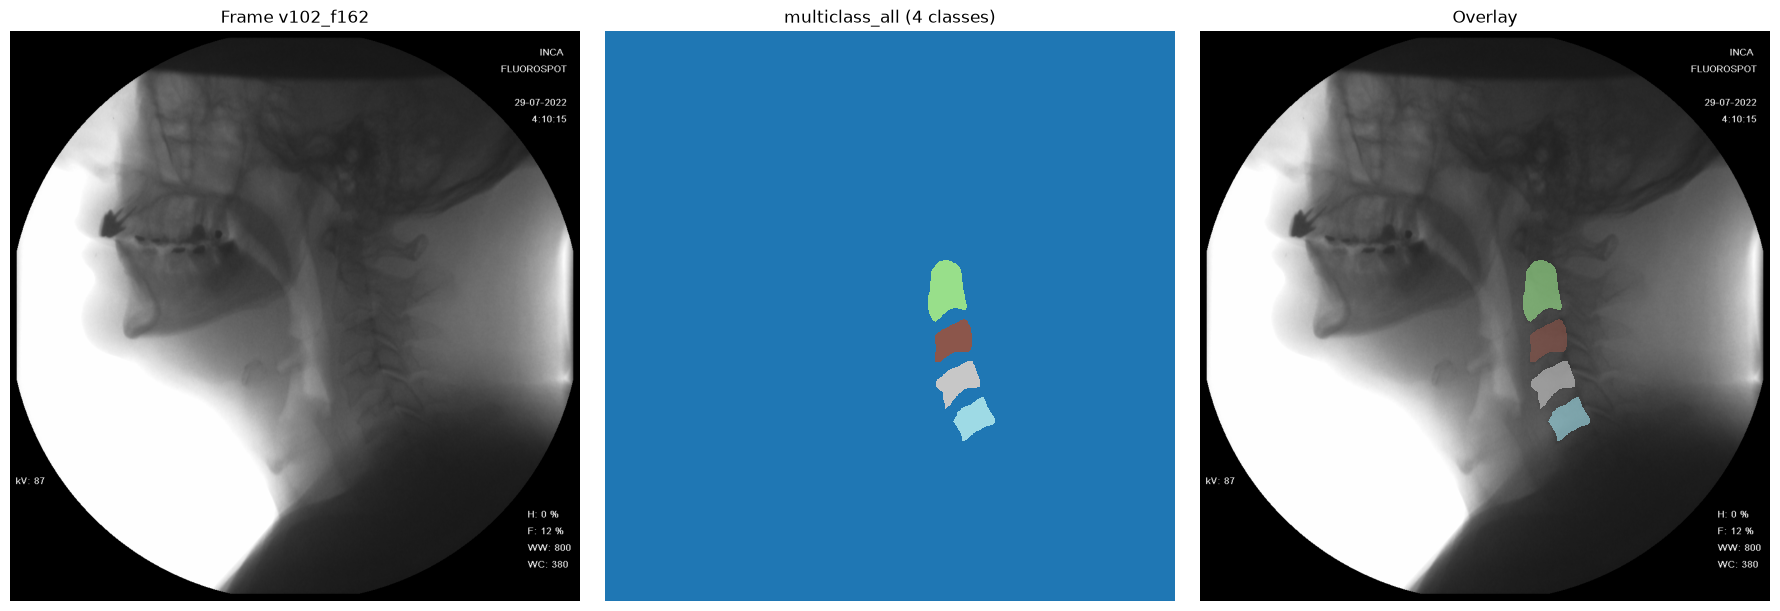

In [ ]:
MULTICLASS_TEST_VARIANT = "multiclass_all"
MULTICLASS_TEST_INDEX = 10  # posicao em mask_index

row = mask_index.iloc[int(np.clip(MULTICLASS_TEST_INDEX, 0, len(mask_index) - 1))]
multiclass_test_path = DATASET_ROOT / variant_relative_path(
    TARGET_TYPE, MULTICLASS_TEST_VARIANT, row["labeler"], row["video_frame"]
)
if not multiclass_test_path.exists():
    raise FileNotFoundError(
        f"{multiclass_test_path} não existe. Gere a variante {MULTICLASS_TEST_VARIANT!r} primeiro."
    )

multiclass_mask = load_image(multiclass_test_path)
multiclass_frame = normalize_image_for_display(load_image(row["image_path"]))

n_classes = int(multiclass_mask.max())
print("Máscara:", multiclass_test_path)
print("Frame:  ", row["image_path"])
print("Shape:", multiclass_mask.shape, "| classes presentes:", sorted(np.unique(multiclass_mask).tolist()))

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
axes[0].imshow(multiclass_frame, cmap="gray")
axes[0].set_title(f"Frame {row['video_frame']}")
axes[0].axis("off")
axes[1].imshow(multiclass_mask, cmap="tab20", interpolation="nearest", vmin=0, vmax=max(n_classes, 1))
axes[1].set_title(f"{MULTICLASS_TEST_VARIANT} ({n_classes} classes)")
axes[1].axis("off")
axes[2].imshow(multiclass_frame, cmap="gray")
axes[2].imshow(np.ma.masked_where(multiclass_mask == 0, multiclass_mask),
               cmap="tab20", interpolation="nearest", alpha=0.65, vmin=0, vmax=max(n_classes, 1))
axes[2].set_title("Overlay")
axes[2].axis("off")
plt.tight_layout()
